In [1]:
import pandas as pd
import requests 
from bs4 import BeautifulSoup 

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [4]:
headers = { "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 " "(KHTML, like Gecko) Chrome/129.0.0.0 Safari/537.36", "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8", "Accept-Language": "en-US,en;q=0.9", "Referer": "https://www.ambitionbox.com/", } 


In [6]:

webpage = requests.get('https://www.ambitionbox.com/list-of-companies?campaign=desktop_nav&page=3', headers = headers).text
#by hitting on URL, we brought entire html code in here 

In [ ]:
soup = BeautifulSoup(webpage, 'lxml')   #html parser. make html parsing easy 

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   Top Companies in India | AmbitionBox
  </title>
  <meta content="Top Companies in India | AmbitionBox" name="title"/>
  <meta content="Get detailed information of top Companies in India shared by employees through reviews, salaries, interview questions, benefits and more." name="description"/>
  <meta content="width=device-width,initial-scale=1, minimum-scale=1, interactive-widget=resizes-content" name="viewport"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_16x16.png" rel="icon" sizes="16x16" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_32x32.png" rel="icon" sizes="32x32" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_48x48.png" rel="icon" sizes="48x48" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/brows
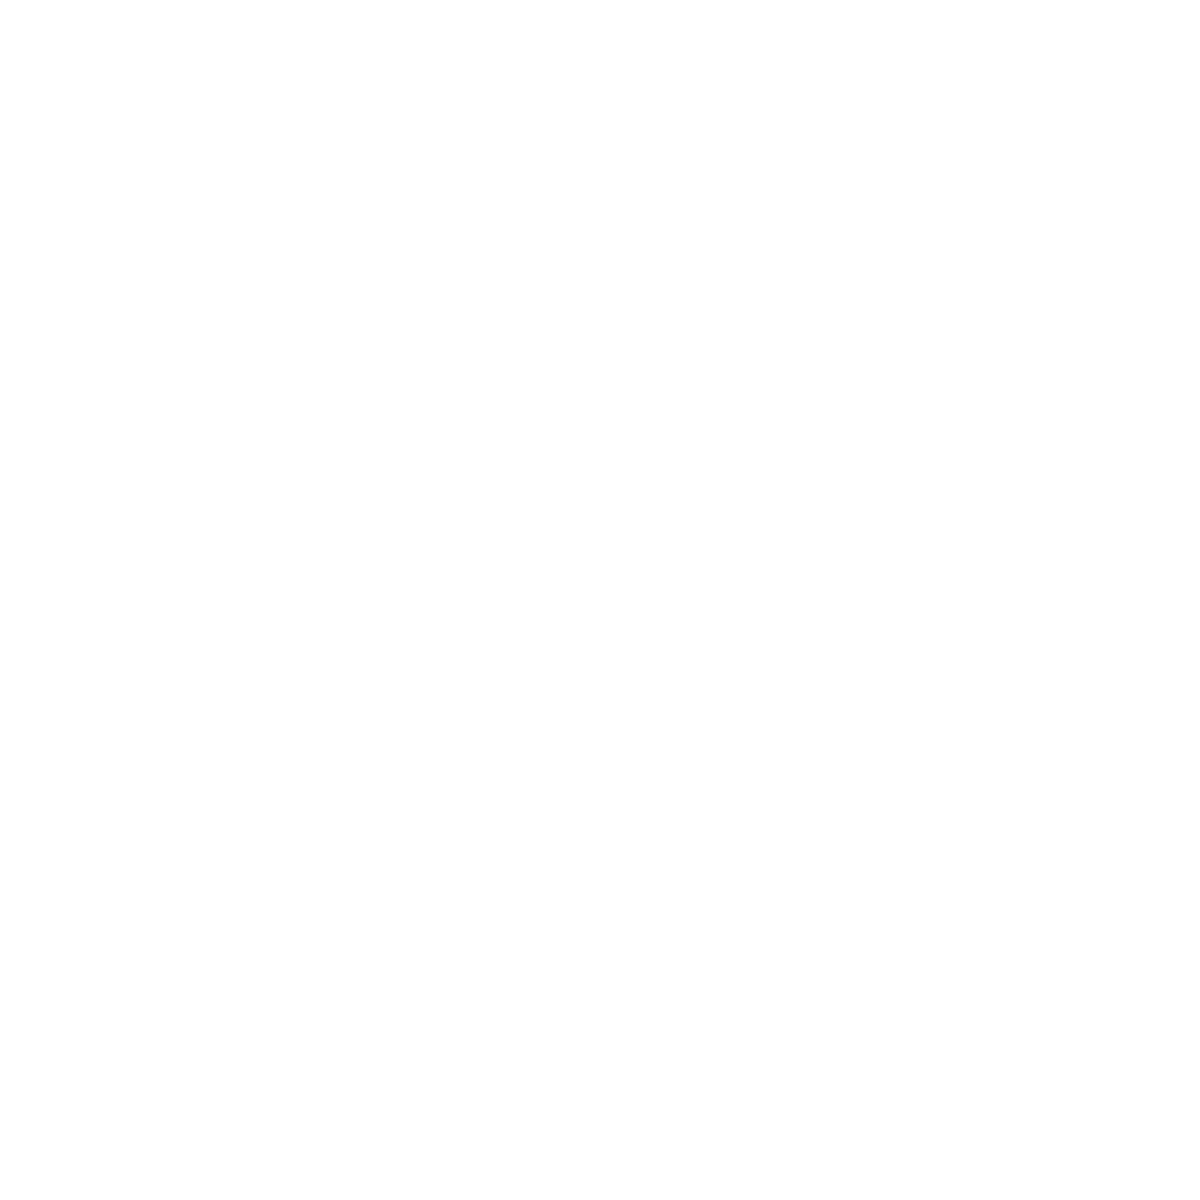

In [70]:
print(soup.prettify()) 

In [71]:
 soup.find_all('h1')[0].text


'List of companies in India'

In [72]:
for i in soup.find_all('h2'):
    print(i.text.strip())

Infosys BPM
DXC Technology
Bandhan Bank
Digitide Solutions
Yes Bank
Quess
Mphasis
Tata Steel
Maruti Suzuki
UltraTech Cement
Startek
Asian Paints
Bajaj Finance
Paytm
Sutherland Global Services
Shriram Finance
Coforge
Equitas Small Finance Bank
Wells Fargo
Cipla


In [73]:
company = soup.find_all('div',class_='company-content-wrapper')
len(company)

0

In [74]:
rating 

[]

In [79]:
name = []
rating = []
reviews = []
ctype = []
hq = []
old = []
employees = []

for i in company:
    name.append(i.find('h2').text.strip())
    rating.append(i.find('p',class_='rating').text.strip())
    reviews.append(i.find('a',class_='review_count').text.strip())
    hq.append(i.find_all('p',class_='infoEntity')[0].text.strip())
    old.append(i.find_all('p',class_='infoEntity')[0].text.strip())
    try:
        employees.append(i.find_all('p',class_='infoEntity')[0].text.strip())
    except:
        employees.append(np.nan)


d = {'name': name,'rating':rating,'reviews':reviews,'type':ctype,'hq':hq,'old':old,'employees':employees}
df = pd.DataFrame(d)


In [80]:
df

,name,rating,reviews,type,hq,old,employees
